In [1]:
%pip install -q faster-whisper sentence-transformers lightgbm spacy
!python -m spacy download en_core_web_sm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 19.8 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 58.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 51.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 70.3 MB/s eta 0:00:00:00:0100:01
Note: you may need to restart the kernel to use updated packages.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 89.8 MB/s eta 0:00:0000:010:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [1]:
# ============ CONFIG ============
STAGE = 2       # 1 = acoustic baseline | 2 = + Whisper encoder | 3 = + transcripts | 4 = blend + submission

import os, json, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm
import torch
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("STAGE", STAGE, "| device:", device)

ROOT = next(Path("/kaggle/input").glob("*/Dataset_Final"), None) or next(Path("/kaggle/input").rglob("Dataset_Final"))
WORK = Path("/kaggle/working"); WORK.mkdir(exist_ok=True)
CACHE = WORK / "cache"; CACHE.mkdir(exist_ok=True)

train = pd.read_csv(ROOT / "train.csv")
test = pd.read_csv(ROOT / "test.csv")
ID_COL = train.columns[0]
LABEL_COL = [c for c in train.columns if c != ID_COL and pd.api.types.is_numeric_dtype(train[c])][0]

def resolve_audio(name, split):
    d = ROOT / split
    for cand in (d / name, d / f"{name}.wav"):
        if cand.exists():
            return cand
    return next(d.rglob(f"{Path(name).stem}.*"))

train["path"] = [resolve_audio(n, "train") for n in train[ID_COL].astype(str)]
test["path"] = [resolve_audio(n, "test") for n in test[ID_COL].astype(str)]
y = train[LABEL_COL].values.astype(float)
print(train.shape, test.shape, "| label mean/std:", round(y.mean(), 3), round(y.std(), 3))
assert len(test) == 216

STAGE 2 | device: cuda
(769, 3) (216, 3) | label mean/std: 3.313 1.238


In [2]:
print("shared file names:", len({Path(p).name for p in train.path} & {Path(p).name for p in test.path}))

for p in train.path:
    s = Path(p).stem
    for old, new in [(CACHE/f"enc_{s}.npy", CACHE/f"enc_train_{s}.npy"), (CACHE/f"{s}.json", CACHE/f"train_{s}.json")]:
        if old.exists() and not new.exists(): old.rename(new)

shared file names: 212


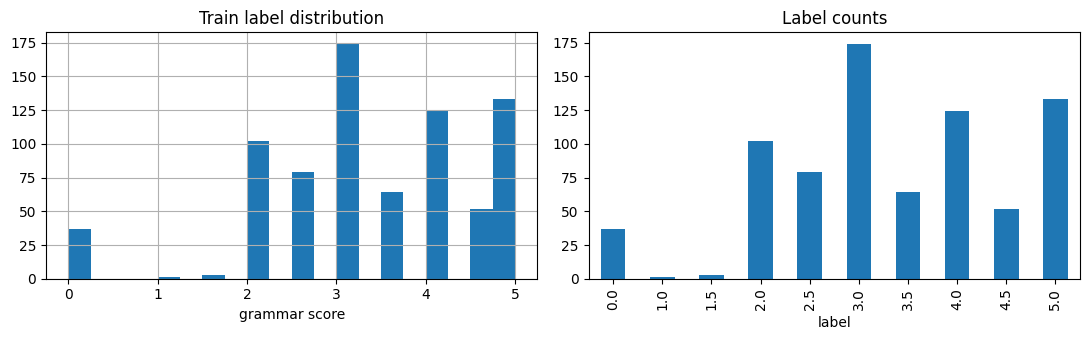

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
train[LABEL_COL].hist(bins=20, ax=ax[0]); ax[0].set_title("Train label distribution"); ax[0].set_xlabel("grammar score")
train[LABEL_COL].value_counts().sort_index().plot.bar(ax=ax[1]); ax[1].set_title("Label counts")
plt.tight_layout(); plt.show()

## Stage 1 - acoustic features and the baseline

In [4]:
if STAGE >= 1:
    import librosa

    def acoustic_feats(path):
        y_, sr = librosa.load(path, sr=16000, mono=True)
        f = {"a_duration": len(y_) / sr}
        rms = librosa.feature.rms(y=y_)[0]
        zcr = librosa.feature.zero_crossing_rate(y_)[0]
        cen = librosa.feature.spectral_centroid(y=y_, sr=sr)[0]
        bw = librosa.feature.spectral_bandwidth(y=y_, sr=sr)[0]
        ro = librosa.feature.spectral_rolloff(y=y_, sr=sr)[0]
        for n, v in [("rms", rms), ("zcr", zcr), ("cent", cen), ("bw", bw), ("roll", ro)]:
            f[f"a_{n}_mean"] = v.mean(); f[f"a_{n}_std"] = v.std()
        f["a_rms_min"] = rms.min(); f["a_rms_max"] = rms.max()
        mf = librosa.feature.mfcc(y=y_, sr=sr, n_mfcc=20)
        for i in range(20):
            f[f"a_mfcc{i}_mean"] = mf[i].mean(); f[f"a_mfcc{i}_std"] = mf[i].std()
        return f

    def cached_acoustic(df, tag):
        fp = CACHE / f"acoustic_{tag}.csv"
        if fp.exists():
            return pd.read_csv(fp)
        out = pd.DataFrame([acoustic_feats(p) for p in tqdm(df.path, desc=f"acoustic {tag}")])
        out.to_csv(fp, index=False); return out

    A_tr = cached_acoustic(train, "train"); A_te = cached_acoustic(test, "test")
    print(A_tr.shape)

acoustic train:   0%|          | 0/769 [00:00<?, ?it/s]

acoustic test:   0%|          | 0/216 [00:00<?, ?it/s]

(769, 53)


In [5]:
if STAGE >= 1:
    # ---- evaluation machinery (same 5 folds for every model, so results are directly comparable) ----
    from sklearn.model_selection import KFold
    from sklearn.linear_model import RidgeCV, LinearRegression
    from sklearn.svm import SVR
    from sklearn.ensemble import ExtraTreesRegressor
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    from scipy.stats import pearsonr
    import lightgbm as lgb

    def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))
    kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
    FOLDS = list(kf.split(y))

    def make_models():
        et = lambda: ExtraTreesRegressor(n_estimators=500, max_features=0.8, n_jobs=-1, random_state=SEED)
        ridge = lambda lo, hi: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(lo, hi, 20)))
        svr = lambda: make_pipeline(StandardScaler(), SVR(C=3.0, epsilon=0.1, gamma="scale"))
        return {   # name: (model, feature-set key)
            "et_acoustic":  (et(), "acou"),                 # STAGE 1 baseline
            "ridge_wenc":   (ridge(1, 5), "wenc"),          # STAGE 2
            "svr_wenc":     (svr(), "wenc"),
            "et_acou_wenc": (et(), "acou_wenc"),
            "et_acou_hand": (et(), "acou_hand"),            # STAGE 3
            "lgbm_hand":    (lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1,
                                               colsample_bytree=0.7, min_child_samples=10, reg_lambda=1.0, random_state=SEED, verbose=-1), "hand"),
            "ridge_text":   (ridge(0, 4), "emb"),
            "svr_text":     (svr(), "emb"),
        }

    FEATS_TR = {"acou": A_tr.values}; FEATS_TE = {"acou": A_te.values}
    OOF = {}

    def evaluate(names):
        for name in names:
            o = np.zeros(len(y))
            for tr_i, va_i in FOLDS:
                m, fs = make_models()[name]
                m.fit(FEATS_TR[fs][tr_i], y[tr_i]); o[va_i] = m.predict(FEATS_TR[fs][va_i])
            OOF[name] = np.clip(o, 0, 5)
        rows = [{"model": n, "oof_rmse": rmse(y, p), "oof_pearson": pearsonr(y, p)[0]} for n, p in OOF.items()]
        tab = pd.DataFrame(rows).sort_values("oof_rmse").reset_index(drop=True)
        if "et_acoustic" in OOF:
            tab["vs_baseline"] = tab.oof_rmse - rmse(y, OOF["et_acoustic"])   # negative = better than baseline
        tab.to_csv(WORK / f"oof_results_stage{STAGE}.csv", index=False)
        print(tab.round(4).to_string(index=False))
        return tab

    print("=== STAGE 1: acoustic baseline (5-fold OOF) ===")
    tab1 = evaluate(["et_acoustic"])

=== STAGE 1: acoustic baseline (5-fold OOF) ===
      model  oof_rmse  oof_pearson  vs_baseline
et_acoustic    0.7537       0.7964          0.0


## Stage 2 - Whisper encoder embeddings of the raw audio

In [6]:
if STAGE >= 2:
    from transformers import WhisperFeatureExtractor, WhisperModel
    ENC_NAME = "openai/whisper-small"
    fe = WhisperFeatureExtractor.from_pretrained(ENC_NAME)
    enc = WhisperModel.from_pretrained(ENC_NAME).encoder.to(device).eval()
    if device == "cuda": enc = enc.half()
    N_LAYERS = enc.config.encoder_layers
    LAYERS = [N_LAYERS // 2, N_LAYERS]            # a middle layer + the last layer

    @torch.no_grad()
    def whisper_embed(path):
        out = CACHE / f"enc_{Path(path).parent.name}_{Path(path).stem}.npy"
        if out.exists(): return np.load(out)
        y_, _ = librosa.load(path, sr=16000, mono=True)
        CH = 30 * 16000                            # Whisper's window is 30 s; clips are 45-60 s -> chunk and average
        chunks = [y_[i:i + CH] for i in range(0, len(y_), CH)]
        if len(chunks) > 1 and len(chunks[-1]) < 16000 * 2: chunks = chunks[:-1]
        vecs, wts = [], []
        for c in chunks:
            feats = fe(c, sampling_rate=16000, return_tensors="pt").input_features.to(device)
            if device == "cuda": feats = feats.half()
            hs = enc(feats, output_hidden_states=True).hidden_states
            valid = max(int(len(c) / 16000 * 50), 1)   # only pool frames that cover real audio, not padding
            vecs.append(np.concatenate([hs[l][0, :valid].float().mean(0).cpu().numpy() for l in LAYERS]))
            wts.append(len(c))
        v = np.average(np.stack(vecs), axis=0, weights=wts).astype("float32")
        np.save(out, v); return v

    W_tr = np.stack([whisper_embed(p) for p in tqdm(train.path, desc="whisper-enc train")])
    W_te = np.stack([whisper_embed(p) for p in tqdm(test.path, desc="whisper-enc test")])
    FEATS_TR["wenc"] = W_tr; FEATS_TE["wenc"] = W_te
    FEATS_TR["acou_wenc"] = np.hstack([A_tr.values, W_tr]); FEATS_TE["acou_wenc"] = np.hstack([A_te.values, W_te])
    print("encoder embeddings:", W_tr.shape)
    print("\n=== STAGE 2: encoder models vs et_acoustic (vs_baseline < 0 means better) ===")
    tab2 = evaluate(["ridge_wenc", "svr_wenc", "et_acou_wenc"])

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

whisper-enc train:   0%|          | 0/769 [00:00<?, ?it/s]

whisper-enc test:   0%|          | 0/216 [00:00<?, ?it/s]

encoder embeddings: (769, 1536)

=== STAGE 2: encoder models vs et_acoustic (vs_baseline < 0 means better) ===
       model  oof_rmse  oof_pearson  vs_baseline
    svr_wenc    0.5530       0.8991      -0.2007
  ridge_wenc    0.5563       0.8945      -0.1974
et_acou_wenc    0.5741       0.8902      -0.1796
 et_acoustic    0.7537       0.7964       0.0000


In [7]:
   names = list(OOF)   # et_acoustic, ridge_wenc, svr_wenc, et_acou_wenc
   S = np.column_stack([OOF[n] for n in names])
   stack = LinearRegression(positive=True).fit(S, y)
   cvp = np.zeros(len(y))
   for a, b in KFold(5, shuffle=True, random_state=1).split(S):
       cvp[b] = LinearRegression(positive=True).fit(S[a], y[a]).predict(S[b])
   print("blend OOF RMSE (cv):", round(rmse(y, np.clip(cvp, 0, 5)), 4),
         "| best single:", round(min(rmse(y, OOF[n]) for n in names), 4))

   test_pred = {}
   for n in names:
       m, fs = make_models()[n]; m.fit(FEATS_TR[fs], y); test_pred[n] = m.predict(FEATS_TE[fs])
   te = np.clip(stack.predict(np.column_stack([test_pred[n] for n in names])), 0, 5)
   sub = pd.DataFrame({"filename": test[ID_COL].values, "label": te})
   assert len(sub) == 216 and sub.label.notna().all()
   sub.to_csv(WORK / "submission_stage2.csv", index=False)
   print(sub.label.describe())

blend OOF RMSE (cv): 0.5239 | best single: 0.553
count    216.000000
mean       3.276332
std        0.790001
min        1.899219
25%        2.640333
50%        3.183473
75%        3.737988
max        5.000000
Name: label, dtype: float64


In [8]:
def load_enc(name):
    fe_ = WhisperFeatureExtractor.from_pretrained(name)
    enc_ = WhisperModel.from_pretrained(name).encoder.to(device).eval()
    return fe_, (enc_.half() if device == "cuda" else enc_)

@torch.no_grad()
def embed_all_layers(path, name, fe_, enc_):
    out = CACHE / f"encall_{name.split('/')[-1]}_{Path(path).parent.name}_{Path(path).stem}.npy"
    if out.exists(): return np.load(out)
    y_, _ = librosa.load(path, sr=16000, mono=True)
    CH = 30 * 16000
    chunks = [y_[i:i + CH] for i in range(0, len(y_), CH)]
    if len(chunks) > 1 and len(chunks[-1]) < 32000: chunks = chunks[:-1]
    vecs, wts = [], []
    for c in chunks:
        f = fe_(c, sampling_rate=16000, return_tensors="pt").input_features.to(device)
        if device == "cuda": f = f.half()
        hs = enc_(f, output_hidden_states=True).hidden_states
        valid = max(int(len(c) / 16000 * 50), 1)
        vecs.append(np.stack([h[0, :valid].float().mean(0).cpu().numpy() for h in hs])); wts.append(len(c))
    v = np.average(np.stack(vecs), axis=0, weights=wts).astype("float32")
    np.save(out, v); return v

MODEL = "openai/whisper-medium"         # then run again with "openai/whisper-medium"
fe_, enc_ = load_enc(MODEL)
ALL_tr = np.stack([embed_all_layers(p, MODEL, fe_, enc_) for p in tqdm(train.path)])
ALL_te = np.stack([embed_all_layers(p, MODEL, fe_, enc_) for p in tqdm(test.path)])

svr = lambda: make_pipeline(StandardScaler(), SVR(C=3.0, epsilon=0.1, gamma="scale"))
def cv_rmse(X):
    o = np.zeros(len(y))
    for a, b in FOLDS:
        m = svr().fit(X[a], y[a]); o[b] = m.predict(X[b])
    return round(rmse(y, np.clip(o, 0, 5)), 4)
for l in range(ALL_tr.shape[1]):
    print(MODEL.split("/")[-1], "layer", l, cv_rmse(ALL_tr[:, l]))

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.99k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.06GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/947 [00:00<?, ?it/s]

  0%|          | 0/769 [00:00<?, ?it/s]

  0%|          | 0/216 [00:00<?, ?it/s]

whisper-medium layer 0 0.7378
whisper-medium layer 1 0.6526
whisper-medium layer 2 0.6244
whisper-medium layer 3 0.6148
whisper-medium layer 4 0.5989
whisper-medium layer 5 0.5949
whisper-medium layer 6 0.5928
whisper-medium layer 7 0.5845
whisper-medium layer 8 0.5759
whisper-medium layer 9 0.5685
whisper-medium layer 10 0.57
whisper-medium layer 11 0.549
whisper-medium layer 12 0.5375
whisper-medium layer 13 0.5426
whisper-medium layer 14 0.541
whisper-medium layer 15 0.5332
whisper-medium layer 16 0.5367
whisper-medium layer 17 0.5325
whisper-medium layer 18 0.5407
whisper-medium layer 19 0.5489
whisper-medium layer 20 0.5537
whisper-medium layer 21 0.5565
whisper-medium layer 22 0.5648
whisper-medium layer 23 0.5628
whisper-medium layer 24 0.5504


In [9]:
   for name, idx in [("avg 7-10", [7, 8, 9, 10]), ("avg 6-11", list(range(6, 12)))]:
       print("small", name, cv_rmse(ALL_tr[:, idx].mean(1)))
   print("small cat 8+9", cv_rmse(ALL_tr[:, [8, 9]].reshape(len(ALL_tr), -1)))

small avg 7-10 0.5678
small avg 6-11 0.5575
small cat 8+9 0.5678


In [10]:
import warnings, numpy as np, pandas as pd, torch, librosa
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.model_selection import KFold
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import pearsonr
from transformers import WhisperFeatureExtractor, WhisperModel
warnings.filterwarnings("ignore")

SEED = 42
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
ROOT = next(Path("/kaggle/input").glob("*/Dataset_Final"), None) or next(Path("/kaggle/input").rglob("Dataset_Final"))
WORK = Path("/kaggle/working"); CACHE = WORK / "cache"; CACHE.mkdir(exist_ok=True, parents=True)

train = pd.read_csv(ROOT / "train.csv"); test = pd.read_csv(ROOT / "test.csv")
ID_COL = train.columns[0]
LABEL_COL = [c for c in train.columns if c != ID_COL and pd.api.types.is_numeric_dtype(train[c])][0]
def resolve_audio(name, split):
    d = ROOT / split
    for cand in (d / name, d / f"{name}.wav"):
        if cand.exists(): return cand
    return next(d.rglob(f"{Path(name).stem}.*"))
train["path"] = [resolve_audio(n, "train") for n in train[ID_COL].astype(str)]
test["path"] = [resolve_audio(n, "test") for n in test[ID_COL].astype(str)]
y = train[LABEL_COL].values.astype(float)
assert len(train) == 769 and len(test) == 216
FOLDS = list(KFold(5, shuffle=True, random_state=SEED).split(y))
def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))

# ---------- acoustic features (cached per split) ----------
def acoustic_feats(path):
    y_, sr = librosa.load(path, sr=16000, mono=True)
    f = {"a_duration": len(y_) / sr}
    rms = librosa.feature.rms(y=y_)[0]; zcr = librosa.feature.zero_crossing_rate(y_)[0]
    cen = librosa.feature.spectral_centroid(y=y_, sr=sr)[0]; bw = librosa.feature.spectral_bandwidth(y=y_, sr=sr)[0]
    ro = librosa.feature.spectral_rolloff(y=y_, sr=sr)[0]
    for n, v in [("rms", rms), ("zcr", zcr), ("cent", cen), ("bw", bw), ("roll", ro)]:
        f[f"a_{n}_mean"] = v.mean(); f[f"a_{n}_std"] = v.std()
    f["a_rms_min"] = rms.min(); f["a_rms_max"] = rms.max()
    mf = librosa.feature.mfcc(y=y_, sr=sr, n_mfcc=20)
    for i in range(20): f[f"a_mfcc{i}_mean"] = mf[i].mean(); f[f"a_mfcc{i}_std"] = mf[i].std()
    return f
def cached_acoustic(df, tag):
    fp = CACHE / f"acoustic_{tag}.csv"
    if fp.exists(): return pd.read_csv(fp)
    out = pd.DataFrame([acoustic_feats(p) for p in tqdm(df.path, desc=f"acoustic {tag}")]); out.to_csv(fp, index=False); return out
A_tr = cached_acoustic(train, "train").values; A_te = cached_acoustic(test, "test").values

# ---------- Whisper encoder embeddings, ALL layers (cache key includes model + split) ----------
@torch.no_grad()
def embed_all_layers(path, tag, fe_, enc_):
    out = CACHE / f"encall_{tag}_{Path(path).parent.name}_{Path(path).stem}.npy"
    if out.exists(): return np.load(out)
    y_, _ = librosa.load(path, sr=16000, mono=True)
    CH = 30 * 16000
    chunks = [y_[i:i + CH] for i in range(0, len(y_), CH)]
    if len(chunks) > 1 and len(chunks[-1]) < 32000: chunks = chunks[:-1]
    vecs, wts = [], []
    for c in chunks:
        f = fe_(c, sampling_rate=16000, return_tensors="pt").input_features.to(device)
        if device == "cuda": f = f.half()
        hs = enc_(f, output_hidden_states=True).hidden_states
        valid = max(int(len(c) / 16000 * 50), 1)
        vecs.append(np.stack([h[0, :valid].float().mean(0).cpu().numpy() for h in hs])); wts.append(len(c))
    v = np.average(np.stack(vecs), axis=0, weights=wts).astype("float32")
    np.save(out, v); return v

def get_layers(name):
    tag = name.split("/")[-1]
    fe_ = WhisperFeatureExtractor.from_pretrained(name)
    enc_ = WhisperModel.from_pretrained(name).encoder.to(device).eval()
    if device == "cuda": enc_ = enc_.half()
    tr = np.stack([embed_all_layers(p, tag, fe_, enc_) for p in tqdm(train.path, desc=f"{tag} train")])
    te = np.stack([embed_all_layers(p, tag, fe_, enc_) for p in tqdm(test.path, desc=f"{tag} test")])
    del enc_; torch.cuda.empty_cache()
    return tr, te
S_tr, S_te = get_layers("openai/whisper-small")
M_tr, M_te = get_layers("openai/whisper-medium")

# ---------- models + blend ----------
FS = {"s9": (S_tr[:, 9], S_te[:, 9]), "m17": (M_tr[:, 17], M_te[:, 17]),
      "m12_17": (M_tr[:, 12:18].mean(1), M_te[:, 12:18].mean(1))}
svr_c = lambda C: (lambda: make_pipeline(StandardScaler(), SVR(C=C, epsilon=0.1, gamma="scale")))
ridge_fn = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(1, 5, 20)))
et_fn = lambda: ExtraTreesRegressor(n_estimators=500, max_features=0.8, n_jobs=-1, random_state=SEED)
def oof_test(Xtr, Xte, fn):
    o = np.zeros(len(y))
    for a, b in FOLDS: o[b] = fn().fit(Xtr[a], y[a]).predict(Xtr[b])
    return np.clip(o, 0, 5), np.clip(fn().fit(Xtr, y).predict(Xte), 0, 5)

scores = {C: round(rmse(y, oof_test(*FS["m12_17"], svr_c(C))[0]), 4) for C in [1, 3, 10, 30]}
print("SVR C -> OOF RMSE:", scores); bestC = min(scores, key=scores.get)
cands = {"et_acoustic": oof_test(A_tr, A_te, et_fn)}
for k, (a, b) in FS.items():
    cands[f"svr_{k}"] = oof_test(a, b, svr_c(bestC)); cands[f"ridge_{k}"] = oof_test(a, b, ridge_fn)
names = list(cands)
S = np.column_stack([cands[n][0] for n in names]); T = np.column_stack([cands[n][1] for n in names])
for n in names: print(f"{n:<14} OOF RMSE {rmse(y, cands[n][0]):.4f}")
cvp = np.zeros(len(y))
for a, b in KFold(5, shuffle=True, random_state=1).split(S):
    cvp[b] = LinearRegression(positive=True).fit(S[a], y[a]).predict(S[b])
print("\nblend OOF RMSE (cv):", round(rmse(y, np.clip(cvp, 0, 5)), 4), "| previous submitted blend: 0.5239")
stack = LinearRegression(positive=True).fit(S, y)
print("weights:", dict(zip(names, np.round(stack.coef_, 3))))
sub = pd.DataFrame({"filename": test[ID_COL].values, "label": np.clip(stack.predict(T), 0, 5)})
assert len(sub) == 216 and sub.label.notna().all() and sub.filename.is_unique
sub.to_csv(WORK / "submission_stage5.csv", index=False); print(sub.label.describe())

device: cuda


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

whisper-small train:   0%|          | 0/769 [00:00<?, ?it/s]

whisper-small test:   0%|          | 0/216 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/947 [00:00<?, ?it/s]

whisper-medium train:   0%|          | 0/769 [00:00<?, ?it/s]

whisper-medium test:   0%|          | 0/216 [00:00<?, ?it/s]

SVR C -> OOF RMSE: {1: 0.5591, 3: 0.5315, 10: 0.531, 30: 0.531}
et_acoustic    OOF RMSE 0.7537
svr_s9         OOF RMSE 0.5521
ridge_s9       OOF RMSE 0.5849
svr_m17        OOF RMSE 0.5327
ridge_m17      OOF RMSE 0.5657
svr_m12_17     OOF RMSE 0.5310
ridge_m12_17   OOF RMSE 0.5709

blend OOF RMSE (cv): 0.5089 | previous submitted blend: 0.5239
weights: {'et_acoustic': np.float64(0.17), 'svr_s9': np.float64(0.16), 'ridge_s9': np.float64(0.0), 'svr_m17': np.float64(0.292), 'ridge_m17': np.float64(0.149), 'svr_m12_17': np.float64(0.379), 'ridge_m12_17': np.float64(0.0)}
count    216.000000
mean       3.255295
std        0.775422
min        1.737665
25%        2.673607
50%        3.141940
75%        3.687425
max        5.000000
Name: label, dtype: float64


In [11]:
from transformers import AutoFeatureExtractor, AutoModel
HM, HTAG = "microsoft/wavlm-large", "wavlm-large"
fe_h = AutoFeatureExtractor.from_pretrained(HM)
hm = AutoModel.from_pretrained(HM).to(device).eval()

@torch.no_grad()
def hub_embed(path):
    out = CACHE / f"hub_{HTAG}_{Path(path).parent.name}_{Path(path).stem}.npy"
    if out.exists(): return np.load(out)
    y_, _ = librosa.load(path, sr=16000, mono=True)
    x = fe_h(y_, sampling_rate=16000, return_tensors="pt").input_values.to(device)
    with torch.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")):
        hs = hm(x, output_hidden_states=True).hidden_states
    H = torch.stack([h[0].float() for h in hs])                    # (layers, time, dim)
    v = torch.cat([H.mean(1), H.std(1)], dim=-1).cpu().numpy().astype("float32")
    np.save(out, v); return v

Wtr = np.stack([hub_embed(p) for p in tqdm(train.path, desc="wavlm train")])
Wte = np.stack([hub_embed(p) for p in tqdm(test.path, desc="wavlm test")])
del hm; torch.cuda.empty_cache()
D = Wtr.shape[2] // 2
print("wavlm features:", Wtr.shape)

def oof_only(X, fn):
    o = np.zeros(len(y))
    for a, b in FOLDS: o[b] = fn().fit(X[a], y[a]).predict(X[b])
    return round(rmse(y, np.clip(o, 0, 5)), 4)

print("\nSVR OOF RMSE per layer (mean pooling):")
layer_scores = {l: oof_only(Wtr[:, l, :D], svr_c(bestC)) for l in range(Wtr.shape[1])}
for l, s in layer_scores.items(): print(" layer", l, s)
bl = min(layer_scores, key=layer_scores.get)
lo, hi = max(bl - 2, 0), min(bl + 3, Wtr.shape[1])
options = {
    f"mean L{bl}":         (Wtr[:, bl, :D],               Wte[:, bl, :D]),
    f"mean+std L{bl}":     (Wtr[:, bl, :],                Wte[:, bl, :]),
    f"mean avg L{lo}-{hi-1}": (Wtr[:, lo:hi, :D].mean(1), Wte[:, lo:hi, :D].mean(1)),
}
opt_scores = {k: oof_only(a, svr_c(bestC)) for k, (a, b) in options.items()}
print("\nfeature options:", opt_scores)
best_opt = min(opt_scores, key=opt_scores.get); Xa, Xb = options[best_opt]
print("using:", best_opt)

c2 = dict(cands)
c2["svr_wavlm"] = oof_test(Xa, Xb, svr_c(bestC))
c2["ridge_wavlm"] = oof_test(Xa, Xb, ridge_fn)
n2 = list(c2)
S2 = np.column_stack([c2[n][0] for n in n2]); T2 = np.column_stack([c2[n][1] for n in n2])
cvp2 = np.zeros(len(y))
for a, b in KFold(5, shuffle=True, random_state=1).split(S2):
    cvp2[b] = LinearRegression(positive=True).fit(S2[a], y[a]).predict(S2[b])
print("\nblend OOF RMSE (cv) with WavLM:", round(rmse(y, np.clip(cvp2, 0, 5)), 4), "| stage 5 blend: 0.5089")
st2 = LinearRegression(positive=True).fit(S2, y)
print("weights:", dict(zip(n2, np.round(st2.coef_, 3))))
sub = pd.DataFrame({"filename": test[ID_COL].values, "label": np.clip(st2.predict(T2), 0, 5)})
assert len(sub) == 216 and sub.label.notna().all() and sub.filename.is_unique
sub.to_csv(WORK / "submission_stage6.csv", index=False); print(sub.label.describe())

preprocessor_config.json:   0%|          | 0.00/214 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.22k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.26GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/488 [00:00<?, ?it/s]

wavlm train:   0%|          | 0/769 [00:00<?, ?it/s]

wavlm test:   0%|          | 0/216 [00:00<?, ?it/s]

wavlm features: (769, 25, 2048)

SVR OOF RMSE per layer (mean pooling):
 layer 0 0.6664
 layer 1 0.6604
 layer 2 0.6263
 layer 3 0.621
 layer 4 0.618
 layer 5 0.6084
 layer 6 0.6121
 layer 7 0.6024
 layer 8 0.5829
 layer 9 0.5552
 layer 10 0.5429
 layer 11 0.5477
 layer 12 0.542
 layer 13 0.5465
 layer 14 0.5473
 layer 15 0.5499
 layer 16 0.546
 layer 17 0.5504
 layer 18 0.5474
 layer 19 0.5506
 layer 20 0.5515
 layer 21 0.5371
 layer 22 0.5474
 layer 23 0.5569
 layer 24 0.5714

feature options: {'mean L21': 0.5371, 'mean+std L21': 0.5415, 'mean avg L19-23': 0.5431}
using: mean L21

blend OOF RMSE (cv) with WavLM: 0.4963 | stage 5 blend: 0.5089
weights: {'et_acoustic': np.float64(0.121), 'svr_s9': np.float64(0.062), 'ridge_s9': np.float64(0.0), 'svr_m17': np.float64(0.205), 'ridge_m17': np.float64(0.0), 'svr_m12_17': np.float64(0.292), 'ridge_m12_17': np.float64(0.0), 'svr_wavlm': np.float64(0.227), 'ridge_wavlm': np.float64(0.229)}
count    216.000000
mean       3.272714
std        0.

In [12]:
# Stage 6.1 — test combinations of the strongest WavLM layers
# No audio/model inference: uses existing Wtr/Wte

ranked = sorted(layer_scores.items(), key=lambda x: x[1])

print("Top individual WavLM layers:")
for l, s in ranked[:8]:
    print(f"Layer {l:2d}: {s:.4f}")

top_layers = [l for l, _ in ranked[:5]]

tests = {}

# Individual top layers
for l in top_layers:
    tests[f"L{l}"] = (
        Wtr[:, l, :D],
        Wte[:, l, :D]
    )

# Concatenate best pairs
for i in range(min(4, len(top_layers))):
    for j in range(i + 1, min(4, len(top_layers))):
        a, b = top_layers[i], top_layers[j]
        tests[f"cat_L{a}_L{b}"] = (
            np.concatenate([Wtr[:, a, :D], Wtr[:, b, :D]], axis=1),
            np.concatenate([Wte[:, a, :D], Wte[:, b, :D]], axis=1)
        )

# Average strongest layers
for k in [2, 3, 4, 5]:
    ls = top_layers[:k]
    tests[f"avg_top{k}"] = (
        Wtr[:, ls, :D].mean(1),
        Wte[:, ls, :D].mean(1)
    )

results = {}

for name, (xtr, xte) in tests.items():
    score = oof_only(xtr, svr_c(bestC))
    results[name] = score
    print(f"{name:<20} {score:.4f}")

print("\nBEST:")
print(min(results.items(), key=lambda x: x[1]))

Top individual WavLM layers:
Layer 21: 0.5371
Layer 12: 0.5420
Layer 10: 0.5429
Layer 16: 0.5460
Layer 13: 0.5465
Layer 14: 0.5473
Layer 18: 0.5474
Layer 22: 0.5474
L21                  0.5371
L12                  0.5420
L10                  0.5429
L16                  0.5460
L13                  0.5465
cat_L21_L12          0.5253
cat_L21_L10          0.5174
cat_L21_L16          0.5364
cat_L12_L10          0.5385
cat_L12_L16          0.5324
cat_L10_L16          0.5249
avg_top2             0.5337
avg_top3             0.5299
avg_top4             0.5309
avg_top5             0.5331

BEST:
('cat_L21_L10', 0.5174)


In [13]:
# ============================================================
# STAGE 6.1 — REBUILD COMPLETE ENSEMBLE WITH WavLM L21 + L10
# ============================================================

# Best WavLM combination from Stage 6.1
Xa = np.concatenate(
    [Wtr[:, 21, :D], Wtr[:, 10, :D]],
    axis=1
)

Xb = np.concatenate(
    [Wte[:, 21, :D], Wte[:, 10, :D]],
    axis=1
)

print("New WavLM train shape:", Xa.shape)
print("New WavLM test shape :", Xb.shape)

# ------------------------------------------------------------
# Add new WavLM models to the existing Stage 6 candidates
# ------------------------------------------------------------
c_new = dict(cands)

c_new["svr_wavlm_L21_L10"] = oof_test(
    Xa,
    Xb,
    svr_c(bestC)
)

c_new["ridge_wavlm_L21_L10"] = oof_test(
    Xa,
    Xb,
    ridge_fn
)

names = list(c_new)

S_new = np.column_stack([
    c_new[n][0] for n in names
])

T_new = np.column_stack([
    c_new[n][1] for n in names
])

# ------------------------------------------------------------
# Cross-validated stack score
# ------------------------------------------------------------
cv_pred = np.zeros(len(y))

for a, b in KFold(
    5,
    shuffle=True,
    random_state=1
).split(S_new):

    meta = LinearRegression(
        positive=True
    )

    meta.fit(S_new[a], y[a])

    cv_pred[b] = meta.predict(S_new[b])

cv_rmse = rmse(
    y,
    np.clip(cv_pred, 0, 5)
)

print("\n======================================")
print("NEW COMPLETE ENSEMBLE")
print("======================================")
print("OOF RMSE:", round(cv_rmse, 4))

# ------------------------------------------------------------
# Fit final stack on all training data
# ------------------------------------------------------------
final_meta = LinearRegression(
    positive=True
)

final_meta.fit(S_new, y)

print("\nWeights:")
for name, weight in zip(names, final_meta.coef_):
    if weight > 0:
        print(f"{name}: {weight:.4f}")

# ------------------------------------------------------------
# Create NEW submission
# ------------------------------------------------------------
new_pred = np.clip(
    final_meta.predict(T_new),
    0,
    5
)

submission_new = pd.DataFrame({
    "filename": test[ID_COL].values,
    "label": new_pred
})

assert len(submission_new) == 216
assert submission_new["label"].notna().all()
assert submission_new["filename"].is_unique

out_path = WORK / "submission_stage6_1.csv"

submission_new.to_csv(
    out_path,
    index=False
)

print("\nSaved:", out_path)
print("\nPrediction statistics:")
print(submission_new["label"].describe())

New WavLM train shape: (769, 2048)
New WavLM test shape : (216, 2048)

NEW COMPLETE ENSEMBLE
OOF RMSE: 0.4919

Weights:
et_acoustic: 0.0969
svr_s9: 0.0346
svr_m17: 0.2629
ridge_m17: 0.0015
svr_m12_17: 0.1804
svr_wavlm_L21_L10: 0.3804
ridge_wavlm_L21_L10: 0.1681

Saved: /kaggle/working/submission_stage6_1.csv

Prediction statistics:
count    216.000000
mean       3.278577
std        0.778881
min        1.827408
25%        2.692623
50%        3.157949
75%        3.710244
max        5.000000
Name: label, dtype: float64


In [14]:
# Final validation before Kaggle submission

sub = pd.read_csv(WORK / "submission_stage6_1.csv")

print("Shape:", sub.shape)
print("Columns:", sub.columns.tolist())
print("Missing values:")
print(sub.isna().sum())
print("Unique filenames:", sub["filename"].nunique())
print("Label range:", sub["label"].min(), sub["label"].max())

assert sub.shape == (216, 2)
assert sub.columns.tolist() == ["filename", "label"]
assert sub["filename"].nunique() == 216
assert sub["label"].notna().all()
assert sub["label"].between(0, 5).all()

print("\nVALID SUBMISSION ✓")

Shape: (216, 2)
Columns: ['filename', 'label']
Missing values:
filename    0
label       0
dtype: int64
Unique filenames: 216
Label range: 1.827407986912044 5.0

VALID SUBMISSION ✓
